# Лабораторная работа №4. Градиент, Laplacian, Canny и морфология

Условие — в [методичке](CSE5382_15_лабораторных_работ_математические_методы_in_CV.md), раздел «Лабораторная работа №4».

**Данные.** `data/building.jpg` (пример OpenCV) для градиентов и Canny; бинарная маска с мелким шумом генерируется в ноутбуке.

## 1. О чём эта работа

### Знакомый пример

Обведите карандашом контуры предметов на фотографии. Вы проводите линию там, где цвет резко меняется: край стола на фоне стены, оконная рама на фоне неба. Там, где цвет меняется плавно (тень на стене), линию вы не проводите. Детектор границ делает то же самое — ищет места резкого изменения яркости.

### Основная идея

«Насколько быстро меняется яркость» — это **производная**. В школьной физике скорость — производная пути по времени; здесь вместо времени координата пикселя. Картинка двумерная, поэтому производных две: по горизонтали и по вертикали. Вместе они образуют стрелку — **градиент**: она показывает, в какую сторону яркость растёт быстрее всего, а её длина — насколько быстро.

### Понятия

- **Производная по $x$**, $I_x$ — разность яркостей соседних пикселей по горизонтали. У пикселей нет «бесконечно малого шага», поэтому используют **центральную разность**: $I_x\approx\frac{I[x+1]-I[x-1]}{2}$ — правый сосед минус левый, делённые на расстояние между ними (2 пикселя).
- **Градиент** $\nabla I=(I_x,I_y)$ — вектор из двух производных. Направлен поперёк границы, от тёмного к светлому.
- **Magnitude** $|\nabla I|$ — длина градиента, «сила границы».
- **Orientation** $\theta$ — угол градиента.
- **Вторая производная** — производная от производной: показывает, как меняется само изменение. **Лапласиан** $\nabla^2I=I_{xx}+I_{yy}$ — сумма вторых производных по обеим осям. На границе первая производная имеет максимум, а вторая проходит через ноль.
- **Canny** — алгоритм из четырёх шагов: сгладить → найти градиент → оставить в каждой «гряде» только гребень (**non-maximum suppression**, утоньшение до 1 пикселя) → оставить сильные границы и те слабые, что с ними соединены (**гистерезис** с двумя порогами: `high` — «точно граница», `low` — «возможно, граница»).
- **Бинарная маска** — картинка из нулей и единиц: «объект / фон».
- **Морфология** — операции над формой областей маски. **Structuring element** — маленький шаблон (у нас квадрат 3×3), которым «ощупывают» маску.
  - **Erosion** (эрозия): пиксель остаётся 1, только если шаблон целиком помещается в объект. Объекты худеют на слой, мелкие точки исчезают.
  - **Dilation** (дилатация): пиксель становится 1, если шаблон хоть краем задевает объект. Объекты толстеют.

### Формулы

$$|\nabla I|=\sqrt{I_x^2+I_y^2},\qquad \theta=\mathrm{atan2}(I_y,\,I_x),\qquad \nabla^2I=I_{xx}+I_{yy}$$

`atan2(y, x)` — арктангенс, который смотрит на знаки обоих аргументов и возвращает угол в полном диапазоне от −180° до 180°.

In [1]:
import cv2
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.dpi": 80, "image.cmap": "gray"})

IMAGE_PATH = "data/building.jpg"
CANNY_PAIRS = [(20, 60), (50, 150), (100, 200), (150, 300)]
rng = np.random.default_rng(0)

## 2. Вопрос 1 — magnitude и угол

> Для Gx=160, Gy=80 найдите magnitude и угол градиента.

**Magnitude** — гипотенуза прямоугольного треугольника с катетами 160 и 80:

$$|G|=\sqrt{160^2+80^2}=\sqrt{25600+6400}=\sqrt{32000}\approx178.89$$

Можно вынести общий множитель: $80\sqrt{2^2+1^2}=80\sqrt5\approx178.89$.

**Угол:** $\theta=\mathrm{atan2}(80,160)=\arctan(0.5)\approx26.565°$.

**Смысл.** По горизонтали яркость меняется вдвое быстрее, чем по вертикали, поэтому стрелка градиента наклонена к горизонтали всего на 26.6°. Граница перпендикулярна градиенту — она идёт под углом ≈116.6°, то есть почти вертикально с небольшим наклоном.

In [2]:
Gx, Gy = 160.0, 80.0
print("|G| =", round(np.hypot(Gx, Gy), 3), " = 80·√5 =", round(80 * np.sqrt(5), 3))
print("θ   =", round(np.degrees(np.arctan2(Gy, Gx)), 3), "°")
print("направление границы:", round(np.degrees(np.arctan2(Gy, Gx)) + 90, 3), "°")
print("\nпочему atan2, а не arctan(Gy/Gx):")
for gx, gy in [(160, 80), (-160, -80), (-160, 80), (0, 80)]:
    naive = np.degrees(np.arctan(gy / gx)) if gx != 0 else float("nan")
    print(f"  G=({gx:5},{gy:4}): arctan(Gy/Gx) = {naive:8.3f}°   atan2 = {np.degrees(np.arctan2(gy, gx)):8.3f}°")

|G| = 178.885  = 80·√5 = 178.885
θ   = 26.565 °
направление границы: 116.565 °

почему atan2, а не arctan(Gy/Gx):
  G=(  160,  80): arctan(Gy/Gx) =   26.565°   atan2 =   26.565°
  G=( -160, -80): arctan(Gy/Gx) =   26.565°   atan2 = -153.435°
  G=( -160,  80): arctan(Gy/Gx) =  -26.565°   atan2 =  153.435°
  G=(    0,  80): arctan(Gy/Gx) =      nan°   atan2 =   90.000°


**Итог вопроса 1:** $|G|\approx178.89$, $\theta\approx26.57°$.

Таблица выше — к первому вопросу защиты: градиенты (160, 80) и (−160, −80) направлены в противоположные стороны, но отношение $G_y/G_x$ у них одинаковое, и `arctan` их не различает. При $G_x=0$ деление вообще невозможно.

## 3. Вопрос 2 — градиент и лапласиан функции

> Для $I(x,y)=3x^2+2xy+4y^2$ найдите ∇I и ∇²I. Объясните, почему вторая производная сильнее усиливает шум.

**Правило.** Частная производная по $x$ считается так, будто $y$ — обычное число.

**Первые производные:**

- $I_x$: от $3x^2$ получаем $6x$; от $2xy$ — $2y$ (здесь $y$ — коэффициент при $x$); от $4y^2$ — 0 (нет $x$). Итого $I_x=6x+2y$.
- $I_y$: от $3x^2$ — 0; от $2xy$ — $2x$; от $4y^2$ — $8y$. Итого $I_y=2x+8y$.

$$\nabla I=(6x+2y,\ 2x+8y)$$

**Вторые производные:** $I_{xx}=\partial(6x+2y)/\partial x=6$, $I_{yy}=\partial(2x+8y)/\partial y=8$.

$$\nabla^2I=6+8=14$$

**Смысл.** Функция — «чаша» (параболоид). Градиент в разных точках разный и указывает от дна чаши наружу. Лапласиан постоянен и положителен: чаша везде одинаково выпукла вниз.

**Почему вторая производная сильнее усиливает шум.** Возьмём самый быстрый шум — чередование $+\varepsilon,-\varepsilon,+\varepsilon,\dots$ Первая разность соседей $(x[n+1]-x[n])$ даёт $\pm2\varepsilon$ — шум удвоился. Вторая разность $(x[n+1]-2x[n]+x[n-1])$ даёт $\pm4\varepsilon$ — учетверился. В общем виде: производная волны $\sin(\omega x)$ равна $\omega\cos(\omega x)$ — амплитуда умножилась на частоту $\omega$; вторая производная умножает на $\omega^2$. Шум — это высокие частоты (большие $\omega$), а полезный сигнал в основном низкие, поэтому каждое дифференцирование ухудшает отношение сигнал/шум, и второе — ещё сильнее.

In [3]:
x, y = sp.symbols("x y")
I_sym = 3 * x ** 2 + 2 * x * y + 4 * y ** 2
Ix_s, Iy_s = sp.diff(I_sym, x), sp.diff(I_sym, y)
print("I_x =", Ix_s, "   I_y =", Iy_s)
print("I_xx =", sp.diff(I_sym, x, 2), "  I_yy =", sp.diff(I_sym, y, 2), "  ∇²I =", sp.diff(I_sym, x, 2) + sp.diff(I_sym, y, 2))

# численная проверка тем же способом, которым будем считать производные изображения
xs, ys = np.meshgrid(np.arange(-5, 6, dtype=float), np.arange(-5, 6, dtype=float))
F = 3 * xs ** 2 + 2 * xs * ys + 4 * ys ** 2
Fx = (F[:, 2:] - F[:, :-2]) / 2
lap = F[1:-1, 2:] + F[1:-1, :-2] + F[2:, 1:-1] + F[:-2, 1:-1] - 4 * F[1:-1, 1:-1]
print("центральная разность I_x совпадает с 6x+2y:", np.allclose(Fx, (6 * xs + 2 * ys)[:, 1:-1]))
print("дискретный лапласиан во всех точках:", np.unique(lap))

# усиление шума: чистый белый шум σ=1 через первую и вторую разность
noise = rng.normal(0, 1, (400, 400))
d1 = (noise[:, 2:] - noise[:, :-2]) / 2
d2 = noise[1:-1, 2:] + noise[1:-1, :-2] + noise[2:, 1:-1] + noise[:-2, 1:-1] - 4 * noise[1:-1, 1:-1]
print(f"\nstd шума на входе 1.00 → после центральной разности {d1.std():.3f} (теория √(1/2)={np.sqrt(0.5):.3f})")
print(f"                      → после лапласиана        {d2.std():.3f} (теория √20={np.sqrt(20):.3f})")

I_x = 6*x + 2*y    I_y = 2*x + 8*y
I_xx = 6   I_yy = 8   ∇²I = 14
центральная разность I_x совпадает с 6x+2y: True
дискретный лапласиан во всех точках: [14.]

std шума на входе 1.00 → после центральной разности 0.707 (теория √(1/2)=0.707)
                      → после лапласиана        4.488 (теория √20=4.472)


**Итог вопроса 2:** $\nabla I=(6x+2y,\ 2x+8y)$, $\nabla^2I=14$.

Последние две строки вывода: шум с $\sigma=1$ после центральной разности стал даже слабее (0.71 — это разность двух отсчётов, делённая на 2), а после лапласиана — в 4.5 раза сильнее. Теоретические значения получаются из суммы квадратов коэффициентов ядра: для $[-\frac12,0,\frac12]$ это $\frac14+\frac14=\frac12$, для лапласиана $1+1+1+1+16=20$.

## 4. Задание 3 — код и эксперимент

### Шаги 1–3. Grayscale float, центральные разности, magnitude и orientation

В массиве изображения первый индекс — строка (ось $y$, вниз), второй — столбец (ось $x$, вправо). Поэтому $I_x$ — разность вдоль второго индекса. На крайних столбцах и строках у пикселя нет одного из соседей, там оставляем нули.

shape: (600, 868) dtype: float64
диапазон Ix: -94.0 96.5   максимум magnitude: 105.12


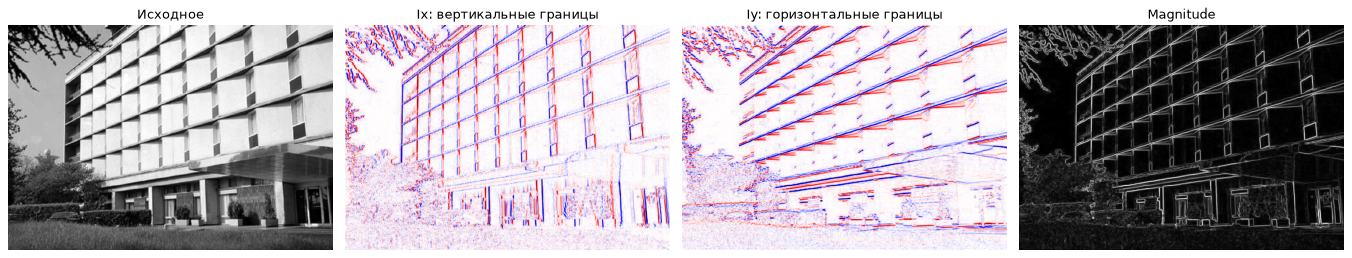

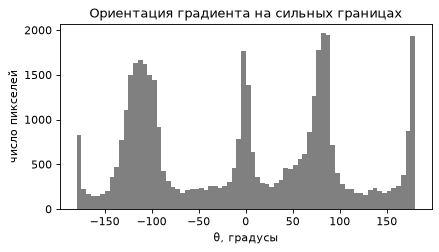

In [4]:
gray = cv2.imread(IMAGE_PATH, cv2.IMREAD_GRAYSCALE).astype(np.float64)
print("shape:", gray.shape, "dtype:", gray.dtype)

Ix = np.zeros_like(gray)
Iy = np.zeros_like(gray)
Ix[:, 1:-1] = (gray[:, 2:] - gray[:, :-2]) / 2.0     # правый сосед минус левый
Iy[1:-1, :] = (gray[2:, :] - gray[:-2, :]) / 2.0     # нижний сосед минус верхний
mag = np.hypot(Ix, Iy)
ang = np.arctan2(Iy, Ix)

print("диапазон Ix:", Ix.min(), Ix.max(), "  максимум magnitude:", round(mag.max(), 2))

fig, ax = plt.subplots(1, 4, figsize=(17, 3.6))
ax[0].imshow(gray); ax[0].set_title("Исходное")
ax[1].imshow(Ix, cmap="seismic", vmin=-80, vmax=80); ax[1].set_title("Ix: вертикальные границы")
ax[2].imshow(Iy, cmap="seismic", vmin=-80, vmax=80); ax[2].set_title("Iy: горизонтальные границы")
ax[3].imshow(mag, vmax=80); ax[3].set_title("Magnitude")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

# ориентация имеет смысл только там, где градиент заметен
strong = mag > 30
plt.figure(figsize=(6, 3))
plt.hist(np.degrees(ang[strong]), bins=72, color="gray")
plt.title("Ориентация градиента на сильных границах"); plt.xlabel("θ, градусы"); plt.ylabel("число пикселей"); plt.show()

На гистограмме ориентаций пики около 0°/±180° и ±90°: у здания почти все границы вертикальные и горизонтальные, значит градиенты — горизонтальные и вертикальные.

### Шаг 4. Сравнение с `cv2.Sobel`

Ядро Собеля для $I_x$:

$$\begin{bmatrix}-1&0&1\\-2&0&2\\-1&0&1\end{bmatrix}=\begin{bmatrix}1\\2\\1\end{bmatrix}\cdot\begin{bmatrix}-1&0&1\end{bmatrix}$$

Оно сепарабельно (см. лабораторную 3): строка $[-1,0,1]$ — это наша центральная разность без деления на 2, столбец $[1,2,1]$ — сглаживание поперёк. Поэтому:

- Собель в **8 раз больше** по масштабу ($2\times4$): разность без деления на 2 и сумма весов сглаживания 4;
- Собель равен центральной разности, сглаженной по вертикали ядром $[1,2,1]/4$, умноженной на 8.

Проверим обе вещи на внутренней области (без граничных пикселей).

In [5]:
sob_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
sob_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
inner = (slice(2, -2), slice(2, -2))

def compare(a, b, name):
    d = np.abs(a[inner] - b[inner])
    print(f"{name:52}: MAE = {d.mean():8.4f}, max = {d.max():8.4f}, корреляция = {np.corrcoef(a[inner].ravel(), b[inner].ravel())[0, 1]:.4f}")

compare(Ix, sob_x / 8, "Ix (центр. разность) vs Sobel/8")
compare(Iy, sob_y / 8, "Iy (центр. разность) vs Sobel/8")

# сглаживаем свою производную поперёк направления дифференцирования → должен получиться Sobel/8 точно
Ix_s = np.zeros_like(Ix); Ix_s[1:-1] = (Ix[:-2] + 2 * Ix[1:-1] + Ix[2:]) / 4
Iy_s = np.zeros_like(Iy); Iy_s[:, 1:-1] = (Iy[:, :-2] + 2 * Iy[:, 1:-1] + Iy[:, 2:]) / 4
compare(Ix_s, sob_x / 8, "Ix, сглаженная [1,2,1]/4 по вертикали vs Sobel/8")
compare(Iy_s, sob_y / 8, "Iy, сглаженная [1,2,1]/4 по горизонтали vs Sobel/8")

Ix (центр. разность) vs Sobel/8                     : MAE =   0.6296, max =  25.5000, корреляция = 0.9943
Iy (центр. разность) vs Sobel/8                     : MAE =   0.5610, max =  29.0000, корреляция = 0.9968
Ix, сглаженная [1,2,1]/4 по вертикали vs Sobel/8    : MAE =   0.0000, max =   0.0000, корреляция = 1.0000
Iy, сглаженная [1,2,1]/4 по горизонтали vs Sobel/8  : MAE =   0.0000, max =   0.0000, корреляция = 1.0000


Несглаженная центральная разность отличается от Собеля на несколько уровней яркости, но корреляция близка к 1: это одна и та же производная, только Собель дополнительно усредняет три соседние строки и тем самым подавляет шум. После того же сглаживания совпадение точное.

### Шаги 5–6. Canny с разными порогами

Для каждой пары порогов считаем долю edge-пикселей и число **связных компонент** — отдельных кусков границы (пиксели считаются соединёнными, если касаются стороной или углом). Много коротких компонент — признак шума или разорванных контуров.

 Canny low  Canny high  Edge pixels, %  Components   Средняя длина, px
        20          60           18.81        3240                30.2
        50         150           11.71        1049                58.1
       100         200            8.25         814                52.8
       150         300            5.64         437                67.2


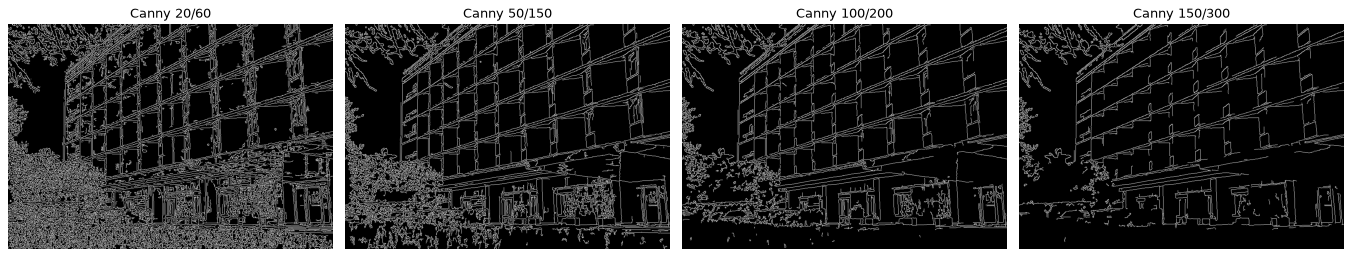

In [6]:
gray_u8 = gray.astype(np.uint8)
canny_res = {}
print(f"{'Canny low':>10}{'Canny high':>12}{'Edge pixels, %':>16}{'Components':>12}{'Средняя длина, px':>20}")
for lo, hi in CANNY_PAIRS:
    e = cv2.Canny(gray_u8, lo, hi)
    n_comp = cv2.connectedComponents(e, connectivity=8)[0] - 1      # минус фон
    pct = 100 * (e > 0).mean()
    canny_res[(lo, hi)] = e
    print(f"{lo:10d}{hi:12d}{pct:16.2f}{n_comp:12d}{(e > 0).sum() / n_comp:20.1f}")

fig, ax = plt.subplots(1, 4, figsize=(17, 3.4))
for a, ((lo, hi), e) in zip(ax, canny_res.items()):
    a.imshow(e); a.set_title(f"Canny {lo}/{hi}"); a.axis("off")
plt.tight_layout(); plt.show()

### Шаги 7–9. Бинарная маска с шумом и собственная эрозия

Маска: два крупных объекта (прямоугольник и круг), тонкая линия шириной 1 пиксель и россыпь шумовых точек.

**Условие эрозии:** выходной пиксель равен 1 только если **все девять** пикселей окна 3×3 вокруг него равны 1. Хватит одного нуля в окне — и на выходе 0.

**Граница маски.** За краем картинки `cv2.erode` по умолчанию считает пиксели «не мешающими» эрозии (как будто там единицы). Чтобы совпасть с OpenCV, дополняем маску единицами.

Реализаций две: с явным двойным циклом (читается как определение) и векторная — логическое И девяти сдвинутых копий маски.

цикл vs векторная, XOR: 0
своя vs cv2.erode, XOR: 0 пикселей различаются
своя dilate vs cv2.dilate, XOR: 0

маска                   площадь  компонент
исходная                  18248        388
erosion                   16796          2
dilation                  22604        290
opening                   17568          2


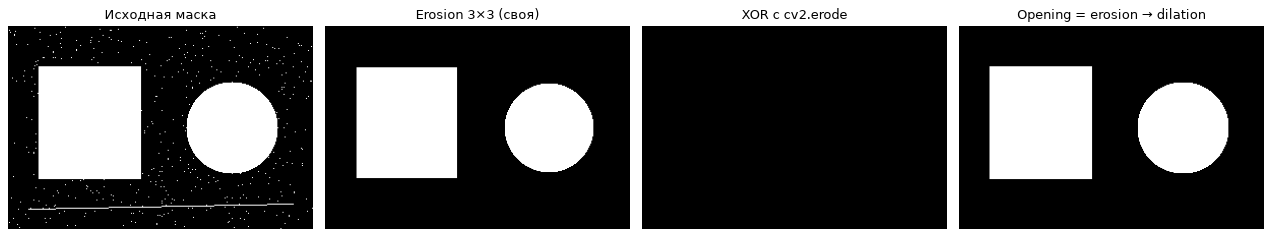

In [7]:
Hm, Wm = 200, 300
mask = np.zeros((Hm, Wm), np.uint8)
cv2.rectangle(mask, (30, 40), (130, 150), 1, -1)
cv2.circle(mask, (220, 100), 45, 1, -1)
cv2.line(mask, (20, 180), (280, 175), 1, 1)                  # тонкая линия шириной 1 px
mask[rng.random((Hm, Wm)) < 0.01] = 1                         # шум: 1 % одиночных точек
mask[:, 0] = 0; mask[0, :] = 0

def erode3_loop(m):
    """Эрозия 3×3: 1 только если всё окно 3×3 принадлежит объекту."""
    p = np.pad(m, 1, constant_values=1)
    out = np.zeros_like(m)
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            out[i, j] = 1 if p[i:i + 3, j:j + 3].all() else 0
    return out

def erode3(m):
    p = np.pad(m, 1, constant_values=1).astype(bool)
    out = np.ones(m.shape, bool)
    for di in range(3):
        for dj in range(3):
            out &= p[di:di + m.shape[0], dj:dj + m.shape[1]]
    return out.astype(np.uint8)

def dilate3(m):
    p = np.pad(m, 1, constant_values=0).astype(bool)
    out = np.zeros(m.shape, bool)
    for di in range(3):
        for dj in range(3):
            out |= p[di:di + m.shape[0], dj:dj + m.shape[1]]
    return out.astype(np.uint8)

kernel = np.ones((3, 3), np.uint8)
er_loop, er_vec, er_cv = erode3_loop(mask), erode3(mask), cv2.erode(mask, kernel)
print("цикл vs векторная, XOR:", int((er_loop ^ er_vec).sum()))
print("своя vs cv2.erode, XOR:", int((er_vec ^ er_cv).sum()), "пикселей различаются")
print("своя dilate vs cv2.dilate, XOR:", int((dilate3(mask) ^ cv2.dilate(mask, kernel)).sum()))

opened = dilate3(erode3(mask))           # opening = эрозия, затем дилатация
def n_comp(m): return cv2.connectedComponents(m, connectivity=8)[0] - 1
print(f"\n{'маска':22}{'площадь':>9}{'компонент':>11}")
for name, m in [("исходная", mask), ("erosion", er_vec), ("dilation", dilate3(mask)), ("opening", opened)]:
    print(f"{name:22}{int(m.sum()):9d}{n_comp(m):11d}")

fig, ax = plt.subplots(1, 4, figsize=(16, 3))
for a, (name, m) in zip(ax, [("Исходная маска", mask), ("Erosion 3×3 (своя)", er_vec), ("XOR с cv2.erode", er_vec ^ er_cv), ("Opening = erosion → dilation", opened)]):
    a.imshow(m, vmin=0, vmax=1); a.set_title(name); a.axis("off")
plt.tight_layout(); plt.show()

Картинка XOR чёрная — различий с OpenCV нет. Эрозия убрала все шумовые точки (ни одна не выдерживает проверки «всё окно 3×3 заполнено»), а opening вернул крупным объектам исходный размер.

## 5. Неудачные случаи

**Морфология.** Тонкая линия шириной 1 пиксель исчезла вместе с шумом: эрозия не отличает «шум» от «тонкого объекта», она знает только размер. Opening её не восстановил — дилатации нечего расширять. Это видно в таблице по площади и на последней картинке.

**Canny на зашумлённом изображении.** Добавим гауссов шум и запустим Canny с теми же порогами.

    пороги     чистое: % / компонент     шум σ=25: % / компонент      шум + Gaussian σ=2
     20/60              18.81 / 3240               36.47 / 11425             7.51 / 1233
    50/150              11.71 / 1049                35.53 / 9073              4.39 / 349
   100/200                8.25 / 814                31.03 / 8590              3.16 / 194
   150/300                5.64 / 437                18.09 / 4565               1.63 / 81


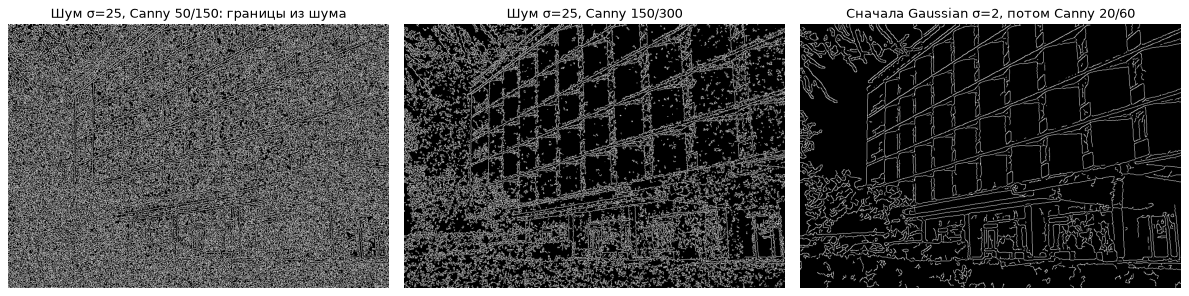

In [8]:
noisy = np.clip(gray + rng.normal(0, 25, gray.shape), 0, 255).astype(np.uint8)
print(f"{'пороги':>10}{'чистое: % / компонент':>26}{'шум σ=25: % / компонент':>28}{'шум + Gaussian σ=2':>24}")
blurred = cv2.GaussianBlur(noisy, (0, 0), 2)
for lo, hi in CANNY_PAIRS:
    row = []
    for im in (gray_u8, noisy, blurred):
        e = cv2.Canny(im, lo, hi)
        row.append(f"{100 * (e > 0).mean():.2f} / {cv2.connectedComponents(e, connectivity=8)[0] - 1}")
    print(f"{f'{lo}/{hi}':>10}{row[0]:>26}{row[1]:>28}{row[2]:>24}")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].imshow(cv2.Canny(noisy, 50, 150)); ax[0].set_title("Шум σ=25, Canny 50/150: границы из шума")
ax[1].imshow(cv2.Canny(noisy, 150, 300)); ax[1].set_title("Шум σ=25, Canny 150/300")
ax[2].imshow(cv2.Canny(blurred, 20, 60)); ax[2].set_title("Сначала Gaussian σ=2, потом Canny 20/60")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

При шуме σ=25 градиент шума сам превышает низкие пороги: Canny честно находит «границы» между случайно более светлыми и более тёмными пикселями, и число компонент растёт на порядок. Поднять пороги — значит потерять слабые настоящие границы. Правильное лечение — сильнее сгладить перед дифференцированием (и тогда пороги нужно снизить, потому что сглаживание уменьшает и градиенты настоящих границ).

## 6. Вывод

Цифры — из таблиц выше для `data/building.jpg`.

- Собственные центральные разности — та же производная, что у Собеля: корреляция с `Sobel/8` ≈ 0.994–0.997, MAE ≈ 0.6 уровня; после сглаживания $[1,2,1]/4$ поперёк направления совпадение точное (MAE = 0). Собель = производная + встроенное сглаживание.
- **Пороги Canny.** С ростом порогов доля edge-пикселей монотонно падает: 18.8 % при 20/60 → 11.7 % при 50/150 → 8.3 % при 100/200 → 5.6 % при 150/300. Число связных компонент — с 3240 до 437. При низких порогах в границы попадает текстура травы и листвы: тысячи коротких обрывков (средняя длина ≈ 30 px). При высоких остаются контуры здания и окон (средняя длина ≈ 67 px), но исчезают слабые границы — облака, тени, детали в затенённом входе.
- **Шум.** На кадре с шумом σ=25 Canny при порогах 50/150 даёт 35.5 % edge-пикселей и 9073 компоненты против 11.7 % и 1049 на чистом: втрое больше «границ» и в девять раз больше обрывков — это границы шума, а не сцены. После гауссова сглаживания σ=2 шумовые границы исчезают, но вместе с ними и мелкая текстура: 4.4 % и 349 компонент — меньше, чем на чистом кадре.
- **Морфология.** Исходная маска — 388 компонент (2 объекта, линия и шум). Эрозия 3×3 оставила только два крупных объекта, уменьшив их на слой в 1 пиксель; opening вернул им размер. Собственная эрозия и дилатация совпали с OpenCV пиксель в пиксель (XOR = 0). Тонкая линия потеряна — это цена: морфология отбирает по размеру, а не по смыслу.
- Вторая производная чувствительнее к шуму: белый шум σ=1 после центральной разности имеет σ ≈ 0.71, после лапласиана ≈ 4.49.

## 7. Вопросы на защиту

**1. Почему для угла нужно использовать atan2, а не arctan(Gy/Gx)?**
`arctan` получает одно число — отношение — и возвращает угол только от −90° до 90°. Он не различает градиенты $(G_x,G_y)$ и $(-G_x,-G_y)$, то есть переход «тёмное→светлое» и «светлое→тёмное», и не определён при $G_x=0$ (вертикальный градиент). `atan2` получает оба числа, по их знакам определяет четверть и возвращает угол от −180° до 180°; при $G_x=0$ даёт ±90°.

**2. Почему Laplacian более чувствителен к шуму и зачем перед ним применяют Gaussian smoothing?**
Дифференцирование умножает амплитуду каждой частоты на саму частоту, двойное — на её квадрат. Шум высокочастотный, поэтому после второй производной его доля резко растёт (в нашем опыте: ×0.71 для первой и ×4.47 для второй). Гауссово сглаживание — low-pass: оно убирает высокие частоты до дифференцирования. Комбинация называется LoG (Laplacian of Gaussian); параметр σ задаёт масштаб границ, которые будут найдены.

**3. Собственная erosion и условие, при котором выходной пиксель остаётся равным 1.**
В `erode3_loop`: `p[i:i+3, j:j+3].all()` — окно 3×3 вокруг пикселя, `.all()` истинно, только если все девять значений ненулевые. То есть structuring element, приложенный центром к пикселю, должен целиком лежать в foreground. В векторной версии то же условие записано как логическое И девяти сдвинутых копий маски. Маска дополнена единицами, чтобы край изображения сам по себе не «съедал» объект — так же поступает OpenCV.